# End-to-End Electricity Theft (Anomaly) Detection in Power Distribution Networks

*English version*

**Goal:** Analyse customers' daily electricity consumption time series to detect non-technical losses (electricity theft) with machine learning, and produce a decision support output that gives field inspection teams a **risk score** for each customer.

**Dataset:** State Grid Corporation of China (SGCC): 42,372 customers, daily consumption from 01.01.2014 to 31.10.2016, `FLAG` (1 = theft).
Source: [Kaggle – SGCC Electricity Theft Detection](https://www.kaggle.com/datasets/bensalem14/sgcc-dataset)

**Method summary**
1. **Preprocessing:** Missing days are filled by linear interpolation along each customer's *own* time series; extreme values are capped per customer (mean + 3σ). All steps work row by row, so there is no leakage between train and test.
2. **Feature engineering:** Besides the raw daily consumption, interpretable features are added: monthly averages, variability, share of zero/missing days, trend slope and number of sudden drops.
3. **Imbalanced data:** SMOTE and XGBoost's `scale_pos_weight` are compared on the validation set.
4. **Model:** XGBoost. Model selection and the decision threshold are chosen on the validation set; the test set is used only for the final evaluation.
5. **Evaluation:** Instead of accuracy: PR-AUC, ROC-AUC, precision/recall, and **Precision@k** and the cumulative gain (lift) curve, which reflect the field inspection scenario.
6. **Explainability:** SHAP for overall feature effects and for explaining the decision for a single customer.


## 0. Setup and settings
The dataset is downloaded directly from Kaggle with `kagglehub` in the settings cell; no manual upload is needed.


In [1]:
!pip install -q shap xgboost imbalanced-learn kagglehub

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve,
                             f1_score, precision_score, recall_score)

RANDOM_STATE = 42
import kagglehub
path = kagglehub.dataset_download("bensalem14/sgcc-dataset")
print(os.listdir(path))
DATA_PATH = os.path.join(path, "data set.csv")
print("Size (MB):", os.path.getsize(DATA_PATH) / 1e6)

IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

def save_fig(name):
    plt.savefig(os.path.join(IMG_DIR, f'{name}.png'), bbox_inches='tight', dpi=150)

100%|██████████| 51.2M/51.2M [00:00<00:00, 110MB/s]

Extracting files...


['data set.csv', 'datasetsmall.csv']
Size (MB): 163.119034


## 1. Loading the data and first checks


In [3]:
data = pd.read_csv(DATA_PATH)
print('Shape:', data.shape)
print('First columns:', data.columns[:3].tolist(), '| Last columns:', data.columns[-3:].tolist())

# Duplicate records
print('Fully duplicated rows:', data.duplicated().sum())
data = data.drop_duplicates()
print('Duplicated customer IDs (CONS_NO):', data['CONS_NO'].duplicated().sum())
data = data.drop_duplicates(subset='CONS_NO', keep='first').reset_index(drop=True)
print('Shape after cleaning:', data.shape)

# Is the file sorted by FLAG?
# If it is, interpolating across rows (axis=0) would leak label information into the model.
n = len(data) // 10
print(f"\nOverall theft rate          : {data['FLAG'].mean():.3f}")
print(f"Rate in first 10% of file  : {data['FLAG'].iloc[:n].mean():.3f}")
print(f"Rate in last 10% of file   : {data['FLAG'].iloc[-n:].mean():.3f}")

Shape: (42372, 1036)
First columns: ['1/1/2014', '1/2/2014', '1/3/2014'] | Last columns: ['10/31/2016', 'CONS_NO', 'FLAG']
Fully duplicated rows: 0
Duplicated customer IDs (CONS_NO): 0
Shape after cleaning: (42372, 1036)

Overall theft rate          : 0.085
Rate in first 10% of file  : 0.123
Rate in last 10% of file   : 0.000


In [4]:
y = data['FLAG'].astype(int)
cons_no = data['CONS_NO'].astype(str)

X_raw = data.drop(columns=['CONS_NO', 'FLAG'])
X_raw.columns = pd.to_datetime(X_raw.columns, format='%m/%d/%Y')
X_raw = X_raw.sort_index(axis=1)          # sort chronologically, to be safe
X_raw = X_raw.astype(float)

print('Number of days:', X_raw.shape[1], '| Date range:', X_raw.columns.min().date(), '→', X_raw.columns.max().date())
print('Share of missing cells: %.2f%%' % (100 * X_raw.isna().values.mean()))

Number of days: 1034 | Date range: 2014-01-01 → 2016-10-31
Share of missing cells: 25.64%


## 2. Exploratory data analysis (EDA)


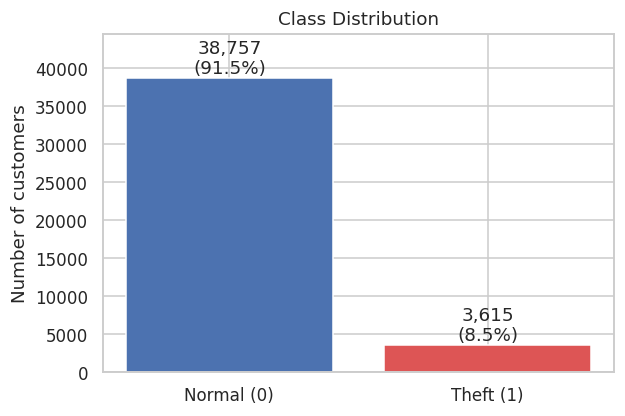

In [5]:
# 2.1 Class distribution
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Normal (0)', 'Theft (1)'], counts.values, color=['#4C72B0', '#DD5555'])
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:,}\n({100 * v / counts.sum():.1f}%)',
            ha='center', va='bottom')
ax.set_title('Class Distribution')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, counts.max() * 1.15)
save_fig('01_class_distribution')
plt.show()

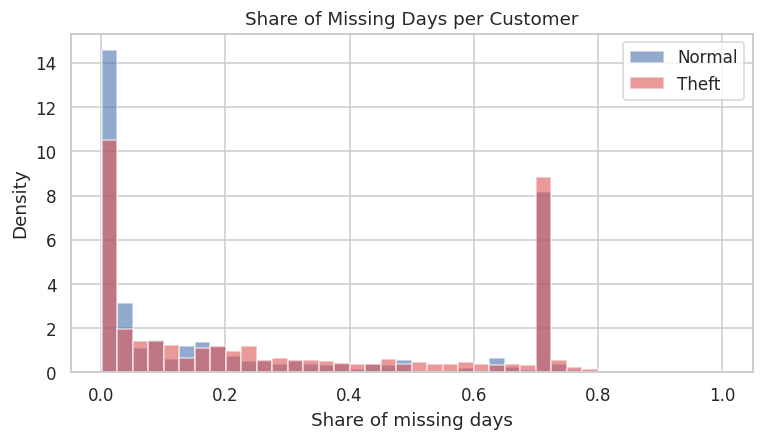

            mean       50%
FLAG                      
Normal  0.250962  0.092843
Theft   0.314687  0.213733


In [6]:
# 2.2 Share of missing days per customer (by class)
missing_ratio = X_raw.isna().mean(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
for label, color, name in [(0, '#4C72B0', 'Normal'), (1, '#DD5555', 'Theft')]:
    ax.hist(missing_ratio[y == label], bins=40, alpha=0.6, density=True, color=color, label=name)
ax.set_title('Share of Missing Days per Customer')
ax.set_xlabel('Share of missing days')
ax.set_ylabel('Density')
ax.legend()
save_fig('02_missing_ratio')
plt.show()

print(missing_ratio.groupby(y).describe()[['mean', '50%']].rename(index={0: 'Normal', 1: 'Theft'}))

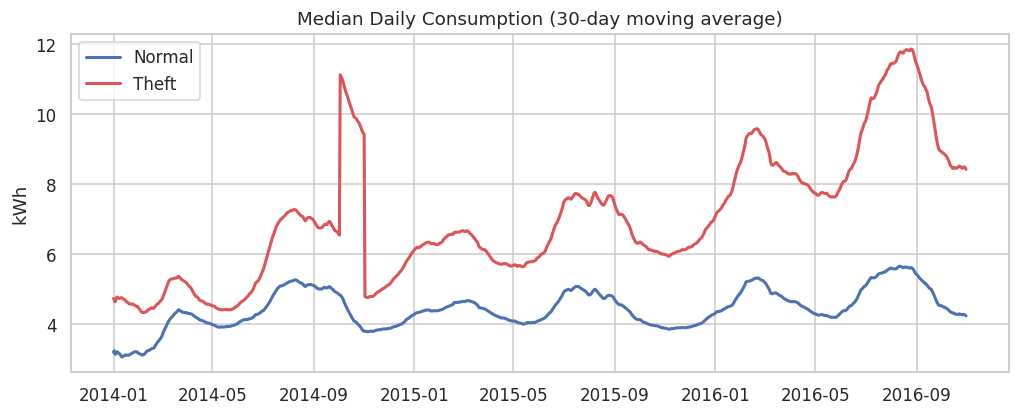

In [7]:
# 2.3 Typical consumption over time (30-day moving median)
fig, ax = plt.subplots(figsize=(11, 4))
for label, color, name in [(0, '#4C72B0', 'Normal'), (1, '#DD5555', 'Theft')]:
    series = X_raw[y == label].median(axis=0, skipna=True).rolling(30, min_periods=1).mean()
    ax.plot(series.index, series.values, color=color, label=name, lw=2)
ax.set_title('Median Daily Consumption (30-day moving average)')
ax.set_ylabel('kWh')
ax.legend()
save_fig('03_consumption_over_time')
plt.show()

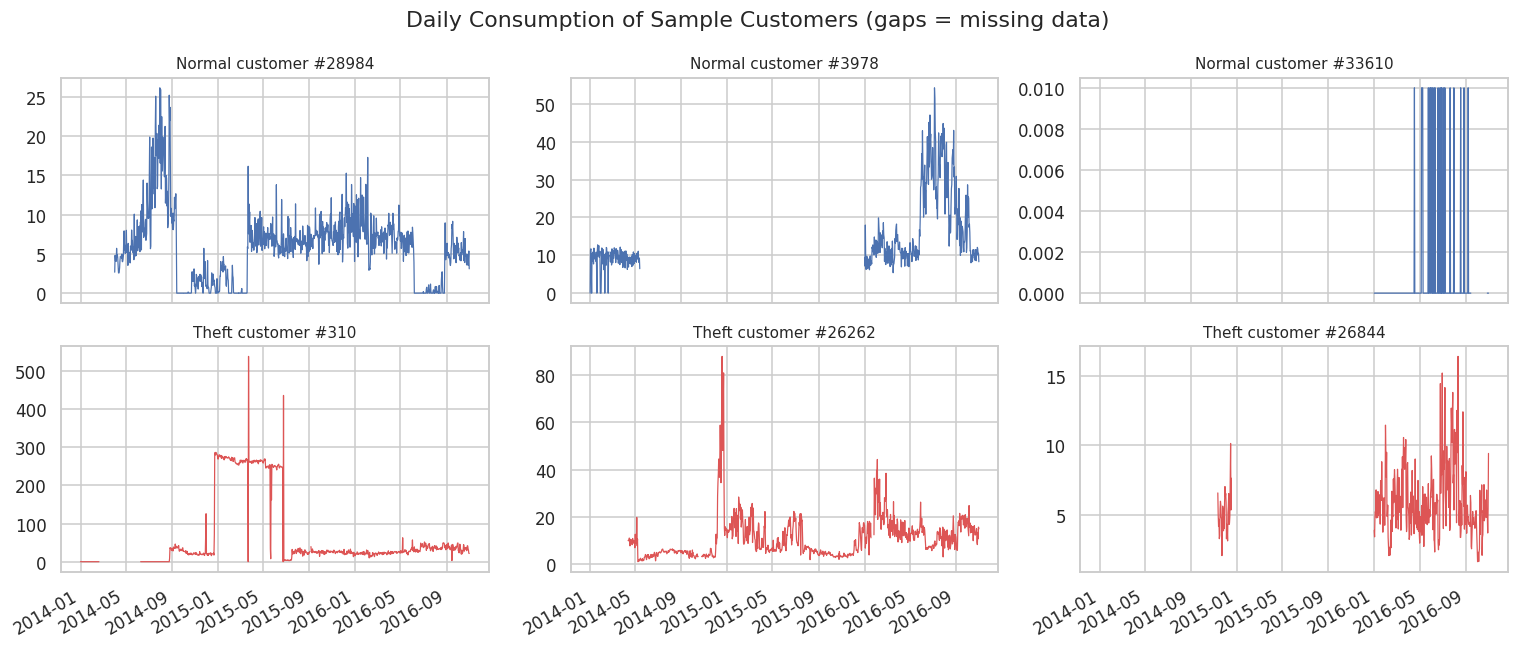

In [8]:
# 2.4 Sample customer profiles
rng = np.random.default_rng(RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True)
for row, (label, color, name) in enumerate([(0, '#4C72B0', 'Normal'), (1, '#DD5555', 'Theft')]):
    ids = rng.choice(np.where(y == label)[0], 3, replace=False)
    for col, i in enumerate(ids):
        axes[row, col].plot(X_raw.columns, X_raw.iloc[i].values, color=color, lw=0.8)
        axes[row, col].set_title(f'{name} customer #{i}', fontsize=10)
fig.suptitle('Daily Consumption of Sample Customers (gaps = missing data)')
fig.autofmt_xdate()
plt.tight_layout()
save_fig('04_sample_customers')
plt.show()

## 3. Preprocessing

- **Interpolation with `axis=1`:** each customer's missing days are filled from *their own* neighbouring days. (The default `axis=0` interpolates across different customers; this makes no sense and, if the file is sorted by FLAG, leaks the label.)
- Customers whose series is completely empty are filled with 0.
- **Extreme values:** for each customer, values above `mean + 3σ` are capped at that limit (to suppress meter reading errors).
- All steps work row by row, so doing them before the train/test split does not cause leakage. XGBoost is tree-based, so no scaling (MinMaxScaler) is needed.


In [9]:
X_filled = X_raw.interpolate(axis=1, limit_direction='both').fillna(0)

row_mean = X_filled.mean(axis=1)
row_std = X_filled.std(axis=1)
X_clean = X_filled.clip(upper=row_mean + 3 * row_std, axis=0)

del X_filled
print('Remaining missing values:', int(X_clean.isna().sum().sum()))

Remaining missing values: 0


## 4. Feature engineering

The raw daily values (1,000+ columns) are informative for the model, but SHAP explanations based on them mean little to a field team ("consumption on 2 January 2014 is important"). So we add interpretable features:

| Feature | Meaning |
|---|---|
| `mean`, `std`, `max`, `median`, `cv` | Overall consumption level and variability |
| `zero_ratio` | Share of days with zero consumption |
| `missing_ratio` | Share of days that could not be read in the original data |
| `trend_slope` | Consumption trend over the whole period |
| `last_vs_first_ratio` | Average of the last 6 months / first 6 months |
| `sudden_drop_count` | Number of months with a drop of more than 50% versus the previous month |
| `month_YYYY-MM` | Average monthly consumption |


In [10]:
def build_features(X_days: pd.DataFrame, missing_ratio: pd.Series) -> pd.DataFrame:
    arr = X_days.values
    eps = 1e-6
    f = pd.DataFrame(index=X_days.index)

    f['mean'] = arr.mean(axis=1)
    f['std'] = arr.std(axis=1)
    f['max'] = arr.max(axis=1)
    f['median'] = np.median(arr, axis=1)
    f['cv'] = f['std'] / (f['mean'] + eps)
    f['zero_ratio'] = (arr == 0).mean(axis=1)
    f['missing_ratio'] = missing_ratio.values

    t = np.arange(arr.shape[1], dtype=float)
    t_c = t - t.mean()
    f['trend_slope'] = (arr - arr.mean(axis=1, keepdims=True)) @ t_c / (t_c ** 2).sum()
    f['last_vs_first_ratio'] = arr[:, -180:].mean(axis=1) / (arr[:, :180].mean(axis=1) + eps)

    # Monthly averages
    months = X_days.columns.to_period('M')
    unique_months = months.unique()
    monthly = np.column_stack([arr[:, months == m].mean(axis=1) for m in unique_months])
    monthly_df = pd.DataFrame(monthly, index=X_days.index,
                              columns=[f'month_{m}' for m in unique_months])

    prev, nxt = monthly[:, :-1], monthly[:, 1:]
    f['sudden_drop_count'] = ((prev > 0) & (nxt < 0.5 * prev)).sum(axis=1)

    return pd.concat([f, monthly_df], axis=1)

X_eng = build_features(X_clean, missing_ratio)

X_daily = X_clean.copy()
X_daily.columns = X_daily.columns.strftime('day_%Y-%m-%d')
X_all = pd.concat([X_daily, X_eng], axis=1)

print('Daily features:', X_daily.shape[1], '| Engineered features:', X_eng.shape[1], '| Total:', X_all.shape[1])
X_eng.iloc[:, :10].groupby(y).median().rename(index={0: 'Normal', 1: 'Theft'}).T

Daily features: 1034 | Engineered features: 44 | Total: 1078


FLAG,Normal,Theft
mean,5.220449,8.325474
std,2.538892,5.117383
max,14.315129,25.106019
median,4.550000,6.917889
cv,0.493608,0.632715
zero_ratio,0.006770,0.002901
missing_ratio,0.092843,0.213733
trend_slope,0.000215,0.003199
last_vs_first_ratio,1.164018,1.732309
sudden_drop_count,1.000000,1.000000


## 5. Train / validation / test split

- **Test (20%):** used only once, at the very end.
- **Validation (20% of the remaining data):** for comparing models and choosing the decision threshold.
- All splits use `stratify`, so the theft rate is the same in every set.


In [11]:
idx = np.arange(len(y))
idx_trval, idx_test = train_test_split(idx, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
idx_tr, idx_val = train_test_split(idx_trval, test_size=0.2, stratify=y.iloc[idx_trval],
                                   random_state=RANDOM_STATE)

for name, ids in [('Train', idx_tr), ('Validation', idx_val), ('Test', idx_test)]:
    print(f'{name:<11}: {len(ids):>6} customers | theft rate: {y.iloc[ids].mean():.3f}')

Train      :  27117 customers | theft rate: 0.085
Validation :   6780 customers | theft rate: 0.085
Test       :   8475 customers | theft rate: 0.085


## 6. Model experiments (validation set)

We compare four combinations: **{daily data only, daily + engineered features} × {SMOTE, scale_pos_weight}**.
Selection criterion: **PR-AUC** (more informative than ROC-AUC on imbalanced data).


In [12]:
def make_model(scale_pos_weight=1.0):
    return XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.5,
        tree_method='hist', eval_metric='aucpr',
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE, n_jobs=-1,
    )

def fit_model(X_tr, y_tr, strategy):
    if strategy == 'SMOTE':
        X_bal, y_bal = SMOTE(random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
        model = make_model()
        model.fit(X_bal, y_bal)
    else:  # scale_pos_weight
        spw = (y_tr == 0).sum() / (y_tr == 1).sum()
        model = make_model(spw)
        model.fit(X_tr, y_tr)
    return model

def precision_at_k(y_true, proba, frac):
    k = max(1, int(len(proba) * frac))
    top = np.argsort(proba)[::-1][:k]
    return np.asarray(y_true)[top].mean()

def evaluate(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        'ROC-AUC': roc_auc_score(y_true, proba),
        'PR-AUC': average_precision_score(y_true, proba),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred),
        'F1': f1_score(y_true, pred),
        'P@5%': precision_at_k(y_true, proba, 0.05),
        'P@10%': precision_at_k(y_true, proba, 0.10),
    }

feature_sets = {'Daily': X_daily, 'Daily + Engineered': X_all}
strategies = ['SMOTE', 'scale_pos_weight']

results, val_probas = [], {}
for fs_name, X_fs in feature_sets.items():
    for strat in strategies:
        key = f'{fs_name} | {strat}'
        print('Training:', key)
        m = fit_model(X_fs.iloc[idx_tr], y.iloc[idx_tr], strat)
        p = m.predict_proba(X_fs.iloc[idx_val])[:, 1]
        val_probas[key] = p
        results.append({'Experiment': key, **evaluate(y.iloc[idx_val], p)})

results_df = pd.DataFrame(results).set_index('Experiment').sort_values('PR-AUC', ascending=False)
results_df.round(3)

Training: Daily | SMOTE
Training: Daily | scale_pos_weight
Training: Daily + Engineered | SMOTE
Training: Daily + Engineered | scale_pos_weight


,ROC-AUC,PR-AUC,Precision,Recall,F1,P@5%,P@10%
Experiment,,,,,,,
Daily + Engineered | scale_pos_weight,0.810,0.405,0.413,0.417,0.415,0.513,0.370
Daily | scale_pos_weight,0.775,0.362,0.403,0.360,0.380,0.499,0.364
Daily + Engineered | SMOTE,0.771,0.358,0.338,0.363,0.350,0.469,0.323
Daily | SMOTE,0.722,0.322,0.273,0.431,0.334,0.442,0.320


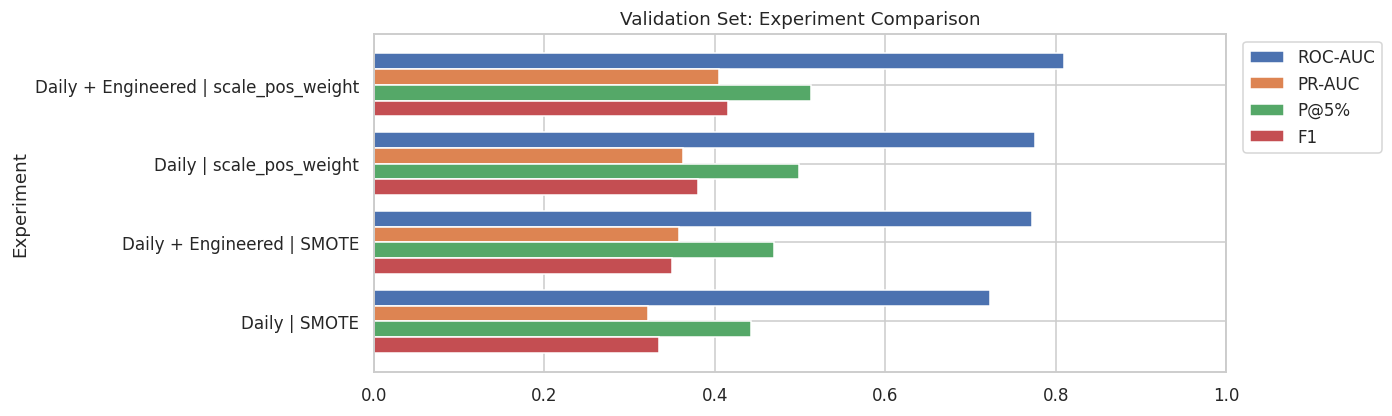

Best experiment: Daily + Engineered | scale_pos_weight


In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
results_df[['ROC-AUC', 'PR-AUC', 'P@5%', 'F1']].plot.barh(ax=ax, width=0.8)
ax.set_title('Validation Set: Experiment Comparison')
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
save_fig('05_experiment_comparison')
plt.show()

best_key = results_df.index[0]
best_fs, best_strat = [s.strip() for s in best_key.split('|')]
print('Best experiment:', best_key)

## 7. Choosing the decision threshold (validation set)

The default threshold of 0.5 is arbitrary. We choose the threshold that **maximises F1** on the validation set.
In practice the threshold can also be set by the field team's inspection capacity (see Section 9, Precision@k).


In [14]:
p_val = val_probas[best_key]
prec, rec, thr = precision_recall_curve(y.iloc[idx_val], p_val)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_threshold = float(thr[np.argmax(f1s)])
print(f'Chosen threshold: {best_threshold:.3f} (validation F1 = {f1s.max():.3f})')

Chosen threshold: 0.500 (validation F1 = 0.415)


## 8. Final model and test set evaluation

The best configuration is retrained on train + validation data and evaluated on the test set **only once**.


In [15]:
X_best = feature_sets[best_fs]
final_model = fit_model(X_best.iloc[idx_trval], y.iloc[idx_trval], best_strat)

X_test = X_best.iloc[idx_test]
y_test = y.iloc[idx_test]
p_test = final_model.predict_proba(X_test)[:, 1]
y_pred = (p_test >= best_threshold).astype(int)

test_summary = pd.DataFrame({
    'Threshold = 0.5': evaluate(y_test, p_test, 0.5),
    f'Threshold = {best_threshold:.2f} (chosen)': evaluate(y_test, p_test, best_threshold),
}).T
print(test_summary.round(3).to_string())
print('\n', classification_report(y_test, y_pred, target_names=['Normal', 'Theft'], digits=3))

                           ROC-AUC  PR-AUC  Precision  Recall     F1   P@5%  P@10%
Threshold = 0.5              0.824   0.429      0.403   0.479  0.438  0.537  0.407
Threshold = 0.50 (chosen)    0.824   0.429      0.403   0.479  0.438  0.537  0.407

               precision    recall  f1-score   support

      Normal      0.951     0.934     0.942      7752
       Theft      0.403     0.479     0.438       723

    accuracy                          0.895      8475
   macro avg      0.677     0.706     0.690      8475
weighted avg      0.904     0.895     0.899      8475



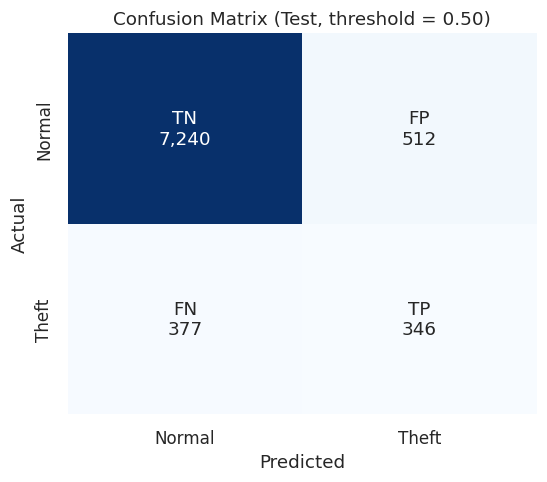

In [16]:
# 8.1 Confusion matrix
cm = confusion_matrix(y_test, y_pred)
labels = np.array([[f'TN\n{cm[0,0]:,}', f'FP\n{cm[0,1]:,}'],
                   [f'FN\n{cm[1,0]:,}', f'TP\n{cm[1,1]:,}']])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Normal', 'Theft'], yticklabels=['Normal', 'Theft'], annot_kws={'size': 12})
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title(f'Confusion Matrix (Test, threshold = {best_threshold:.2f})')
save_fig('06_confusion_matrix')
plt.show()

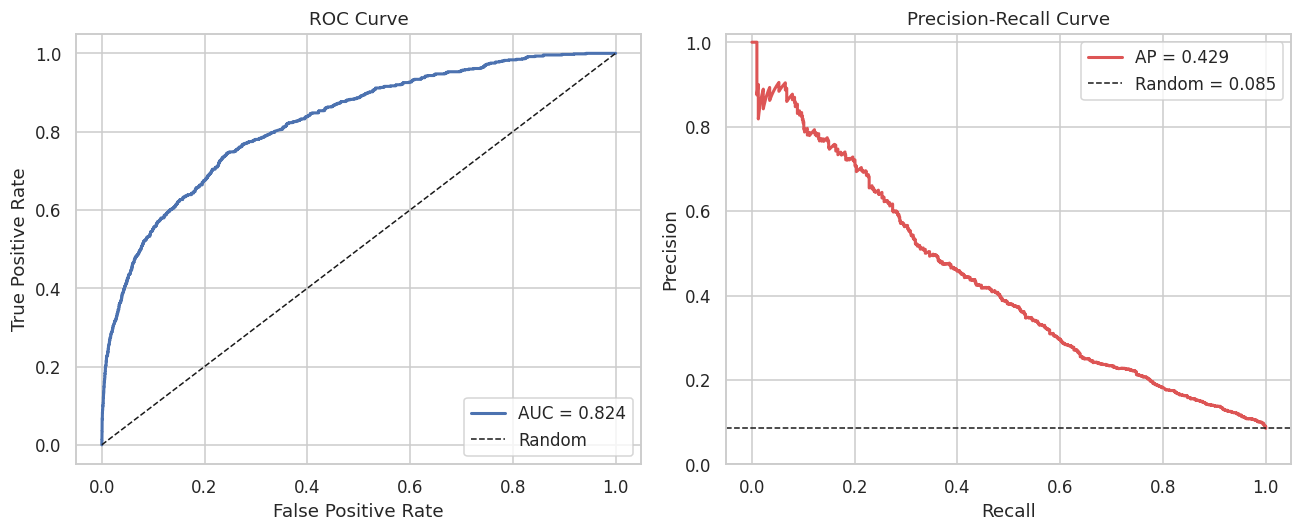

In [17]:
# 8.2 ROC and precision-recall curves
fpr, tpr, _ = roc_curve(y_test, p_test)
prec_t, rec_t, _ = precision_recall_curve(y_test, p_test)
base_rate = y_test.mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y_test, p_test):.3f}')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
axes[0].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC Curve')
axes[0].legend(loc='lower right')

axes[1].plot(rec_t, prec_t, lw=2, color='#DD5555',
             label=f'AP = {average_precision_score(y_test, p_test):.3f}')
axes[1].axhline(base_rate, color='k', ls='--', lw=1, label=f'Random = {base_rate:.3f}')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Precision-Recall Curve', ylim=(0, 1.02))
axes[1].legend(loc='upper right')
plt.tight_layout()
save_fig('07_roc_pr_curves')
plt.show()

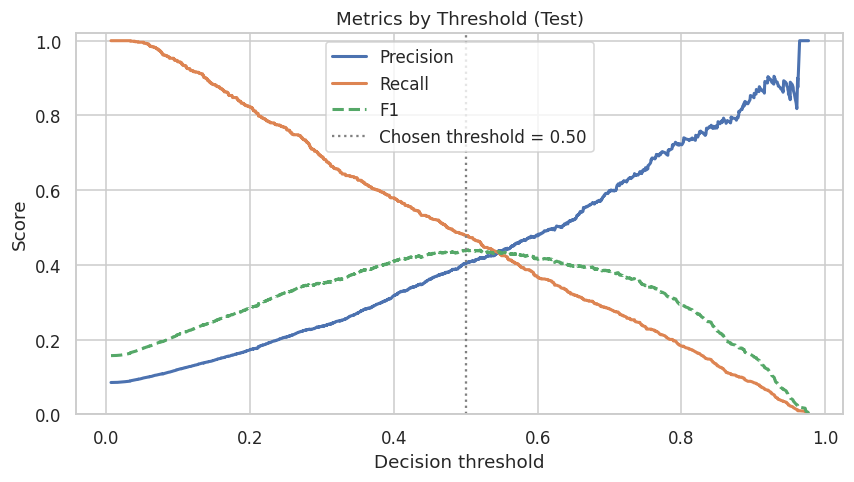

In [18]:
# 8.3 Precision / recall / F1 by threshold
prec_c, rec_c, thr_c = precision_recall_curve(y_test, p_test)
f1_c = 2 * prec_c[:-1] * rec_c[:-1] / (prec_c[:-1] + rec_c[:-1] + 1e-12)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(thr_c, prec_c[:-1], label='Precision', lw=2)
ax.plot(thr_c, rec_c[:-1], label='Recall', lw=2)
ax.plot(thr_c, f1_c, label='F1', lw=2, ls='--')
ax.axvline(best_threshold, color='gray', ls=':', label=f'Chosen threshold = {best_threshold:.2f}')
ax.set(xlabel='Decision threshold', ylabel='Score', title='Metrics by Threshold (Test)', ylim=(0, 1.02))
ax.legend()
save_fig('08_threshold_analysis')
plt.show()

## 9. Field operations view: cumulative gain (lift)

Question: *If we rank customers by risk score and inspect the riskiest X%, what share of the thieves do we catch?*
With random inspections this share grows linearly (the diagonal). The further the model curve is above the diagonal, the better the field teams' time is used.

Results on the test set (8,475 customers, hit rate of random inspection 8.5%):

| Customers inspected | Hit rate of inspections | Versus random | Share of thieves caught |
|---|---|---|---|
| Riskiest 5% | 53.7% | 6.3× | 31.4% |
| Riskiest 10% | 40.7% | 4.8× | 47.7% |
| Riskiest 20% | 27.0% | 3.2× | 63.2% |

This table can guide decisions based on inspection capacity: if capacity is limited, focusing on the riskiest 5% gives the highest hit rate; for wider coverage, inspecting the riskiest 20% reaches about two thirds of the thieves.


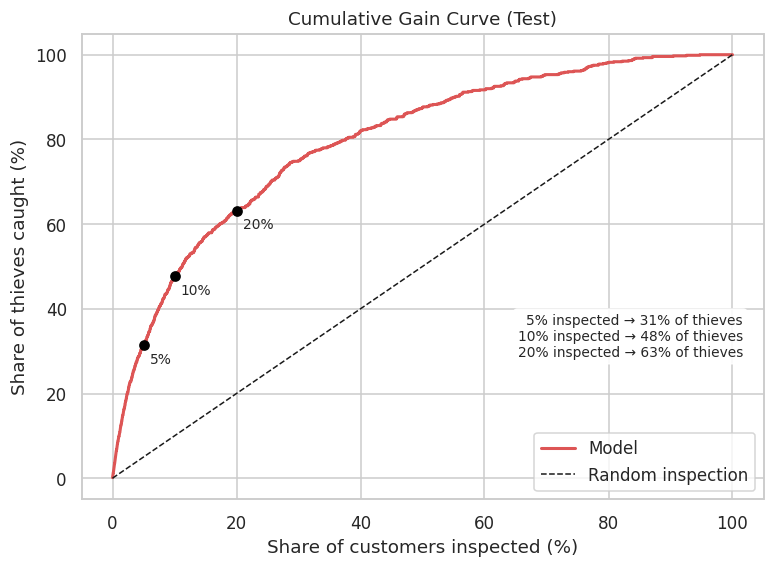

Hit rate of random inspection: 8.5%
Inspecting the riskiest  5%: hit rate 53.7% (6.3x random), 31.4% of thieves caught
Inspecting the riskiest 10%: hit rate 40.7% (4.8x random), 47.7% of thieves caught
Inspecting the riskiest 20%: hit rate 27.0% (3.2x random), 63.2% of thieves caught


In [19]:
order = np.argsort(p_test)[::-1]
y_sorted = y_test.values[order]
frac_inspected = np.arange(1, len(y_sorted) + 1) / len(y_sorted)
frac_caught = np.cumsum(y_sorted) / y_sorted.sum()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(frac_inspected * 100, frac_caught * 100, lw=2, color='#DD5555', label='Model')
ax.plot([0, 100], [0, 100], 'k--', lw=1, label='Random inspection')
summary_lines = []
for pct in [5, 10, 20]:
    i = int(len(y_sorted) * pct / 100) - 1
    ax.scatter(pct, frac_caught[i] * 100, color='black', zorder=5)
    ax.annotate(f'{pct}%', (pct, frac_caught[i] * 100), xytext=(4, -12),
                textcoords='offset points', fontsize=9)
    summary_lines.append(f'{pct}% inspected → {frac_caught[i]*100:.0f}% of thieves')
ax.text(0.97, 0.30, '\n'.join(summary_lines), transform=ax.transAxes, ha='right', va='bottom',
        fontsize=9, bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
ax.set(xlabel='Share of customers inspected (%)', ylabel='Share of thieves caught (%)',
       title='Cumulative Gain Curve (Test)')
ax.legend(loc='lower right')
save_fig('09_cumulative_gain')
plt.show()

print(f'Hit rate of random inspection: {base_rate*100:.1f}%')
for pct in [0.05, 0.10, 0.20]:
    p_at = precision_at_k(y_test, p_test, pct)
    caught = frac_caught[int(len(y_sorted) * pct) - 1]
    print(f'Inspecting the riskiest {int(pct*100):>2}%: hit rate {p_at*100:.1f}% '
          f'({p_at/base_rate:.1f}x random), {caught*100:.1f}% of thieves caught')

## 10. Explainability (SHAP)


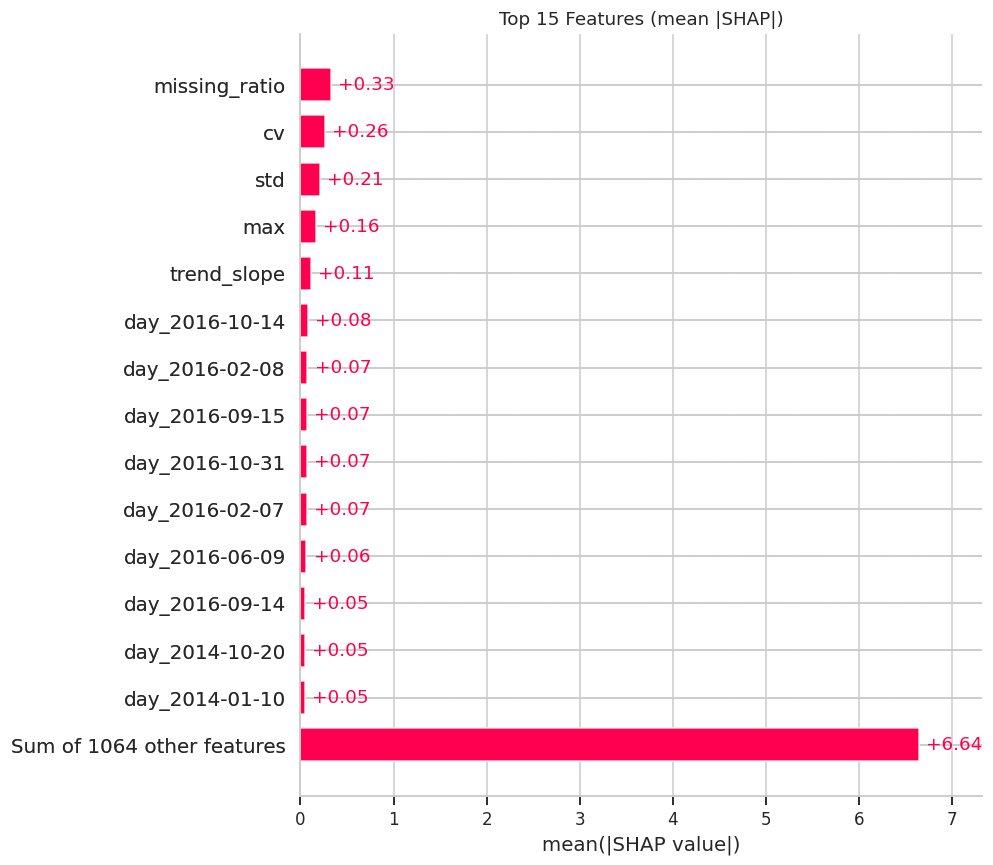

In [20]:
X_shap = X_test.sample(n=min(500, len(X_test)), random_state=RANDOM_STATE)
explainer = shap.TreeExplainer(final_model)
shap_values = explainer(X_shap)

# 10.1 Overall importance ranking
plt.figure()
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title('Top 15 Features (mean |SHAP|)')
save_fig('10_shap_bar')
plt.show()

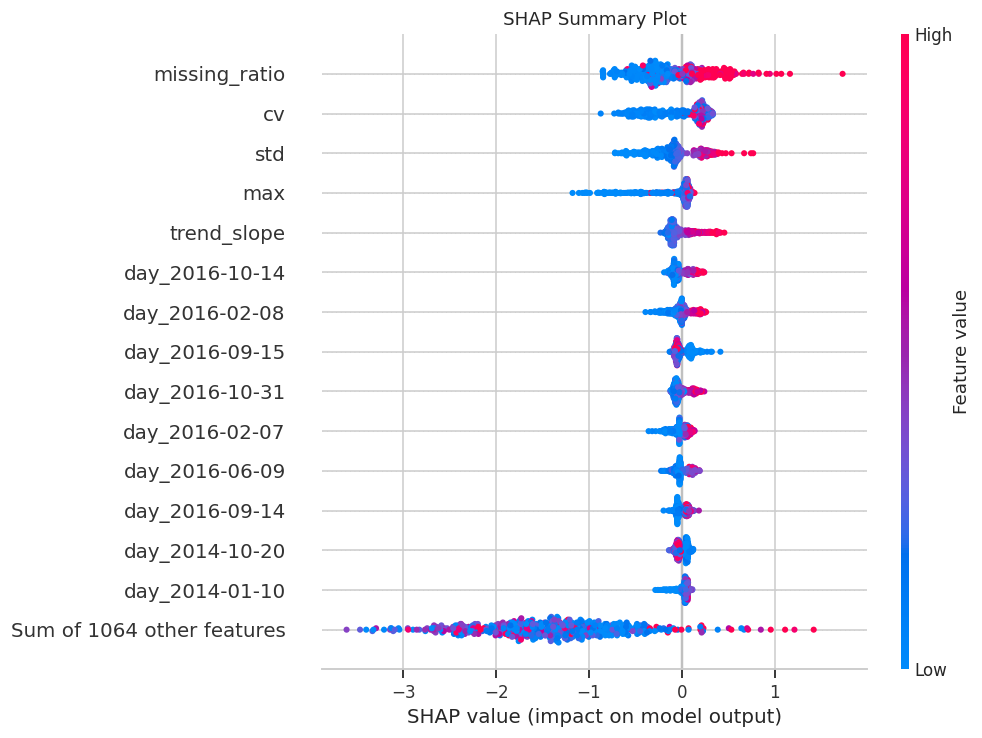

In [21]:
# 10.2 Direction of each feature's effect on the prediction
plt.figure()
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title('SHAP Summary Plot')
save_fig('11_shap_beeswarm')
plt.show()

Customer: 66329AC9964AB7B12DEDC9F63420D9BC | Risk score: 0.977 | True label: 1


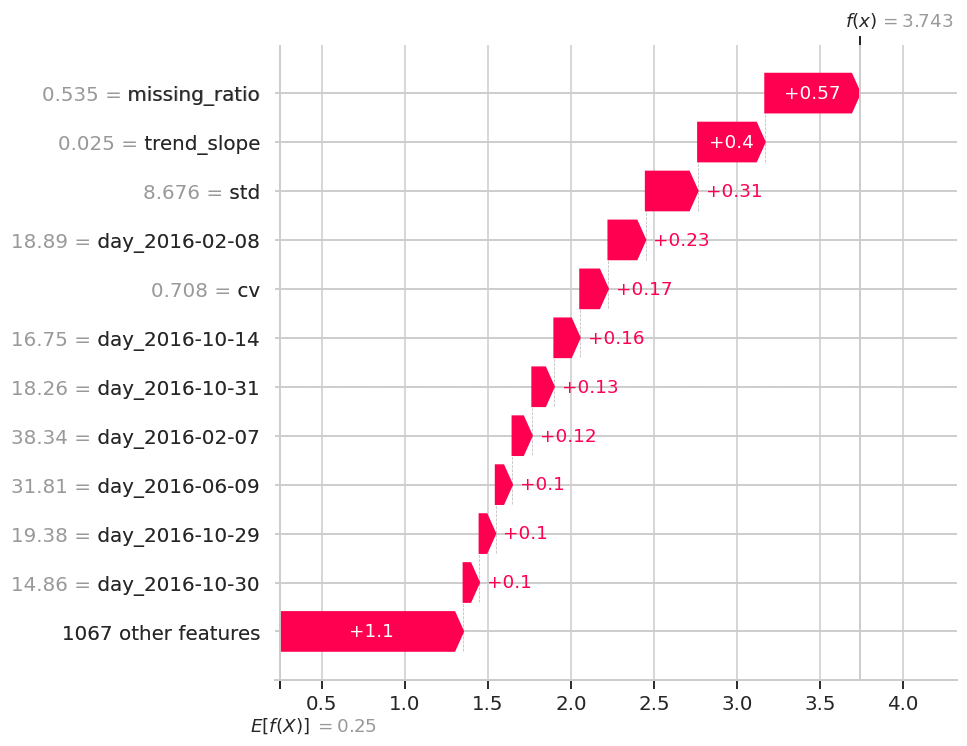

In [22]:
# 10.3 Explaining the decision for one customer (the riskiest customer in the sample)
risk_in_sample = final_model.predict_proba(X_shap)[:, 1]
i_top = int(np.argmax(risk_in_sample))
print(f'Customer: {cons_no.loc[X_shap.index[i_top]]} | Risk score: {risk_in_sample[i_top]:.3f} '
      f'| True label: {y.loc[X_shap.index[i_top]]}')

plt.figure()
shap.plots.waterfall(shap_values[i_top], max_display=12, show=False)
save_fig('12_shap_waterfall')
plt.show()

## 11. Decision support output: risk score list

Customers in the test set are ranked by risk score and split into three levels:
**High** (riskiest 5%), **Medium** (next 10%), **Low** (the rest).

The column names and level labels in `risk_scores_test.csv` stay in Turkish (`risk_skoru` = risk score, `gercek_FLAG` = true label, `risk_seviyesi` = risk level: `Yüksek` = High, `Orta` = Medium, `Düşük` = Low), because the Power BI dashboard reads this file.


In [23]:
risk_df = pd.DataFrame({
    'CONS_NO': cons_no.iloc[idx_test].values,
    'risk_skoru': p_test,
    'gercek_FLAG': y_test.values,
}).sort_values('risk_skoru', ascending=False).reset_index(drop=True)

pct_rank = np.arange(1, len(risk_df) + 1) / len(risk_df)
risk_df['risk_seviyesi'] = np.select([pct_rank <= 0.05, pct_rank <= 0.15], ['Yüksek', 'Orta'], 'Düşük')

risk_df.to_csv('risk_scores_test.csv', index=False)
print(risk_df.groupby('risk_seviyesi', sort=False)['gercek_FLAG'].agg(['count', 'mean'])
      .rename(columns={'count': 'customers', 'mean': 'true theft rate'}).round(3))
risk_df.head(20)

               customers  true theft rate
risk_seviyesi                            
Yüksek               423            0.537
Orta                 848            0.218
Düşük               7204            0.043


,CONS_NO,risk_skoru,gercek_FLAG,risk_seviyesi
0,66329AC9964AB7B12DEDC9F63420D9BC,0.976866,1,Yüksek
1,825E19825195633229E0E0BD91F412AB,0.976293,1,Yüksek
2,397C84F9F2AEF73869F12D82B3D54DE3,0.973383,1,Yüksek
3,FF2D183CFEE4E2372324887BE3B9ABBE,0.972876,1,Yüksek
4,35C0690E0AF7174AC19F5644DC5233A0,0.972682,1,Yüksek
5,F1D26619E4BC428924BAF5261F705D18,0.972202,1,Yüksek
6,1B173C1A3A2EEF026D089EE150A5AA51,0.964519,1,Yüksek
7,6AF38DF12C3E0B41D71C838E30022B95,0.962004,0,Yüksek
8,0C72D35CD3E76A966E65946FB1FA912D,0.961724,1,Yüksek
9,A0A399DE0D59698E41BE2E4C6AAE3DE7,0.961697,1,Yüksek


## 12. Results and business outputs

### Model selection (validation set)

| Experiment | ROC-AUC | PR-AUC | F1 | P@5% |
|---|---|---|---|---|
| **Daily + Engineered, scale_pos_weight** | **0.810** | **0.405** | **0.415** | **0.513** |
| Daily, scale_pos_weight | 0.775 | 0.362 | 0.380 | 0.499 |
| Daily + Engineered, SMOTE | 0.771 | 0.358 | 0.350 | 0.469 |
| Daily, SMOTE | 0.722 | 0.322 | 0.334 | 0.442 |

- **`scale_pos_weight` beat SMOTE with both feature sets.** On 1,000+ dimensional time series, SMOTE interpolates between the consumption curves of two customers and creates unrealistic synthetic customers; class weighting stays true to the real data.
- **The engineered features improved performance with both methods** (PR-AUC 0.362 → 0.405 in the best configuration).

### Test set results

The final model (Daily + Engineered, scale_pos_weight) was retrained on train + validation data and evaluated once on the test set. The threshold that maximised F1 on the validation set matched the default of 0.5.

| Metric | Value | Random model |
|---|---|---|
| ROC-AUC | 0.824 | 0.500 |
| PR-AUC | 0.429 | 0.085 |
| Precision (theft) | 0.403 | 0.085 |
| Recall (theft) | 0.479 | – |
| F1 (theft) | 0.438 | – |

- **About 346 of the 723 thieves** in the test set were caught.
- The model raised an alarm for about 859 customers; **about 40 of every 100 are real thieves**. Inspecting the same number of random addresses would find about 73 thieves (**≈ 4.7× more efficient**).
- **Why is accuracy not reported?** The model's accuracy is 0.895. A naive model that calls everyone "normal" and finds no thieves at all gets 91.5% accuracy. So in this problem, accuracy makes a useful model look worse than a useless one.

### Decision support output: risk levels

| Risk level | Customers | True theft rate |
|---|---|---|
| High (riskiest 5%) | 423 | 53.7% |
| Medium (next 10%) | 848 | 21.8% |
| Low (remaining 85%) | 7,204 | 4.3% |

The levels separate clearly. The theft rate in the "Low" group is half the overall average (8.5%), so the model also identifies reasonably well the customers who do not need an inspection. All test customers are saved in `risk_scores_test.csv`.

### Explainability (SHAP)

- **All of the five most influential features are engineered features:** `missing_ratio`, `cv`, `std`, `max`, `trend_slope`.
- **Patterns that raise risk:** a high share of unread days, volatile consumption and an upward trend over time. A low maximum consumption is a strong "normal" signal.
- Among the daily features, the most influential ones are mostly from the last months of 2016; the model gives weight to recent consumption.
- However, the combined contribution of the remaining 1,064 features is much larger than any single feature; the model's decision is spread over thousands of daily values. This limits explainability.
- Note: SHAP values are in **log-odds**, not probabilities (for example, f(x) = 3.74 in the waterfall plot corresponds to a risk score of 0.977).

### Limitations

- **Label noise:** labels come from past inspections; thieves who were never caught may be labelled "normal".
- **Possible selection bias:** thieves have higher and more volatile consumption. This may be because large consumers are more likely to steal, or because inspection teams check such customers more often.
- **`missing_ratio` may be a shortcut:** the strongest signal is the share of unread days. This may be a real trace of meter tampering, or a data collection effect where unreadable meters are inspected more often. In the second case the model may be learning "customers likely to be inspected" rather than "thieves".
- **Long missing periods:** gaps of several months were filled by interpolation; this is reasonable for short gaps but an artificial estimate for long ones.
- **Data quality:** some customers have almost no readings; they may affect the metrics somewhat.
- **Generalisation:** the data comes from one region and period; it has not been tested on other networks.
- **Missing context:** the model uses only consumption data; weather, holidays and customer type could reduce false alarms.

### Differences from earlier / reference approaches

- **Interpolation axis fixed:** missing days were filled along each customer's own time series (`axis=1`), not across customers (`axis=0`). Because the row order of the data file is related to the label (the last 10% of the file contains no thieves at all), filling across rows is meaningless and potentially misleading.
- **Train/test leakage removed:** the MinMaxScaler fitted on all data and the filling with column means were removed. Missing value filling and capping use only each customer's own data (row by row); since the tree-based model does not need scaling, the scaling step was dropped.
- **Separate validation set:** model selection and threshold tuning were done on the validation set; the test set was looked at only once.
- **Field-focused evaluation:** PR-AUC, Precision@k and cumulative gain instead of accuracy.
- **Comparison of results:** the reference approach reports about 0.65 precision/recall, while the corrected pipeline reaches 0.40 precision and 0.48 recall. This work did not measure which change causes the difference, but the new results reflect a methodologically correct evaluation without leakage.


In [24]:
# Optional (Google Colab): download the saved figures as one zip file
import shutil
shutil.make_archive('images', 'zip', IMG_DIR)
try:
    from google.colab import files
    files.download('images.zip')
except ImportError:
    print('Figures saved in', IMG_DIR, 'and images.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>